# ASCENT 4-130, Module 3 : Architecture des agents intelligents

**Formation** : Les agents autonomes et aide à la décision (Jour 1, module 3, 2 heures).

**Objectifs du module**

- Distinguer les modèles réactif, délibératif et hybride.
- Comprendre l'intégration des modules de perception, de décision et d'action.
- Discuter les défis d'implémentation en environnement réel.

**Fil rouge** : le même robot d'entrepôt est piloté successivement par trois contrôleurs que nous écrivons dans ce notebook, puis confronté à trois scénarios : une zone dégagée, un cul-de-sac et un entrepôt où une palette imprévue apparaît.

**Travaux pratiques du syllabus** : concevoir l'architecture d'un agent pour un cas pratique spécifique.

| Partie | Contenu | Durée indicative |
|---|---|---|
| 1 | Trois façons d'assembler perception, décision et action | 5 min |
| 2 | Contrôleur réactif | 10 min |
| 3 | Contrôleur délibératif et A* | 20 min |
| 4 | Contrôleur hybride | 10 min |
| 5 | Comparaison sur les mêmes scénarios | 10 min |
| 6 | Complexité croissante et limites | 10 min |
| 7 | TP de conception | 10 min, puis travail autonome |

A* et les contrôleurs sont des algorithmes séquentiels à base de files et de dictionnaires : ils s'exécutent sur CPU et le GPU n'y apporte rien.

## Avant de commencer

**Ce qu'il faut connaître.** Chaque notion utilisée ici a sa leçon guidée dans le module 0 du site. Si l'une d'elles vous est nouvelle, commencez par là (15 à 20 minutes par leçon, théorie et atelier de construction compris) :

- [Boucle perception, décision, action](https://martinobettucci.github.io/4-120/#/module/0/boucle)
- [Architecture réactive](https://martinobettucci.github.io/4-120/#/module/0/reactif)
- [Planifier avec A*](https://martinobettucci.github.io/4-120/#/module/0/astar)
- [Architecture hybride](https://martinobettucci.github.io/4-120/#/module/0/hybride)

**Comment travailler dans ce notebook.** Pour chaque partie, suivez quatre temps :

1. **Lire** l'explication qui précède le code.
2. **Prédire** ce que la cellule va afficher, avant de l'exécuter. Notez votre prédiction, même approximative.
3. **Exécuter**, puis comparer le résultat à votre prédiction. Un écart est une information : cherchez d'où il vient.
4. **Modifier** une valeur de la cellule `PARAMETRES`, relancer, et expliquer en une phrase ce qui a changé.

**Dans les exercices**, l'aide est graduée : essayez d'abord seul, relisez ensuite l'exemple qui précède, et n'ouvrez la « Solution possible » qu'après un essai. Comparer sa propre tentative à la solution apprend davantage que la lire directement.

In [1]:
# Installation automatique (Colab ou poste sans le paquet). Sans effet si tout est déjà installé.
import importlib.util, subprocess, sys
if importlib.util.find_spec("ascent_agents") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ascent-agents[complet] @ https://martinobettucci.github.io/4-120/dist/ascent_agents-1.0.0-py3-none-any.whl"])

In [2]:
import heapq
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ascent_agents import ACTIONS, creer_scenario, detecter_appareil, fixer_graines, simuler
from ascent_agents.agents import AgentDeliberatif, AgentHybride, AgentReactif
from ascent_agents.monde import Chariot, Entrepot, Evenement, entrepot_aleatoire
from ascent_agents.visualisation import BLEU, GRIS, JAUNE, NOIR, PALETTE, ROUGE, VERT, dessiner_monde, dessiner_trace, style

APPAREIL = detecter_appareil()   # affiché pour information : ce module reste sur CPU
fixer_graines(4130)
style()
RESULTATS = Path("resultats")
RESULTATS.mkdir(exist_ok=True)
DIRECTIONS = ["N", "E", "S", "O"]
OPPOSE = {"N": "S", "S": "N", "E": "O", "O": "E"}

Aucun GPU CUDA detecte : repli sur CPU (tous les notebooks restent executables).
PyTorch 2.15.0+cpu


## 1. Trois façons d'assembler perception, décision et action

| Architecture | Chemin de l'information | Ce que l'agent possède | Force | Faiblesse |
|---|---|---|---|---|
| Réactive | capteurs → règles → effecteurs | Rien d'autre que la mesure courante | Rapide, robuste à l'imprévu local | Pas de vision d'ensemble, minimums locaux |
| Délibérative | capteurs → modèle du monde → planification → effecteurs | Une carte et un plan complet | Trajet optimal sur le modèle | Lente à planifier, fragile si le monde diffère du modèle |
| Hybride | couche délibérative (plan) supervisée par une couche réactive (sécurité) | Les deux | Vision d'ensemble et réflexes | Arbitrage entre les couches à concevoir |

Les trois contrôleurs respectent la même interface : `reinitialiser(monde)` puis `decider(observation)`, qui retourne l'action et une explication. Seule la partie décision change : la perception (lidar, position) et l'action (cinq commandes) sont identiques.

## 2. Contrôleur réactif

Des règles stimulus vers réponse, sans carte ni plan. La seule mémoire est la dernière action, pour éviter un demi-tour immédiat.

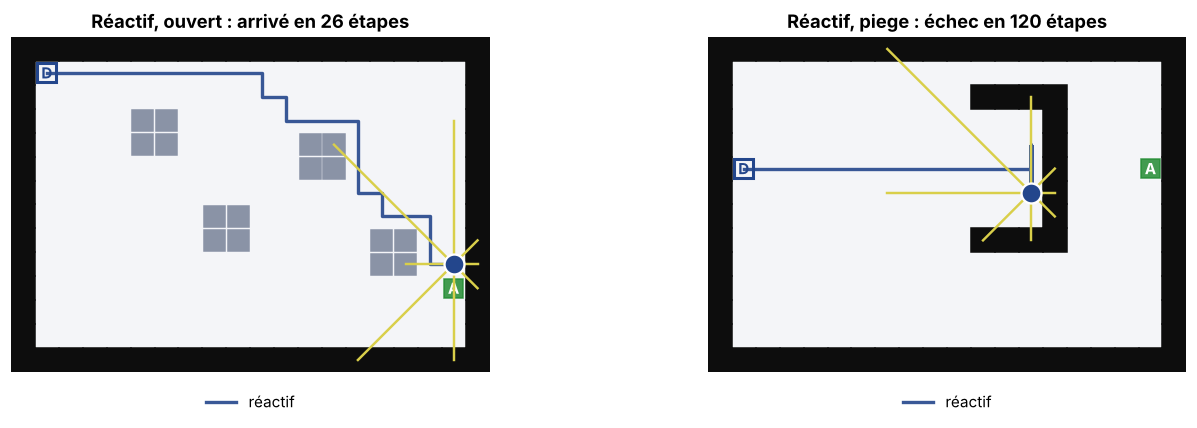

In [3]:
class Reactif:
    nom = "réactif"

    def reinitialiser(self, monde):
        self.derniere = None

    def decider(self, observation):
        lidar = observation["lidar"]
        dx, dy = observation["cap_objectif"]
        # Directions qui rapprochent de l'objectif, la plus utile d'abord.
        souhaits = []
        if dx != 0:
            souhaits.append("E" if dx > 0 else "O")
        if dy != 0:
            souhaits.append("S" if dy > 0 else "N")
        if abs(dy) > abs(dx):
            souhaits.reverse()
        libres = [a for a in DIRECTIONS if lidar[a] > 1]
        # Règle 1 : si une direction utile est libre, la prendre.
        for a in souhaits:
            if a in libres:
                self.derniere = a
                return a, {"couche": "reactive", "raison": f"R1, voie libre vers l'objectif : {a}"}
        # Règle 2 : sinon contourner, sans faire demi-tour.
        autres = [a for a in libres if a != OPPOSE.get(self.derniere)]
        if autres:
            a = self.derniere if self.derniere in autres else autres[0]
            self.derniere = a
            return a, {"couche": "reactive", "raison": f"R2, contournement par {a}"}
        # Règle 3 : demi-tour en dernier recours.
        if libres:
            self.derniere = libres[0]
            return libres[0], {"couche": "reactive", "raison": "R3, demi-tour"}
        return "ATTENDRE", {"couche": "reactive", "raison": "R4, encerclé"}


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, scenario in zip(axes, ["ouvert", "piege"]):
    trace = simuler(creer_scenario(scenario), Reactif(), max_etapes=120)
    dessiner_trace(trace, ax=ax, titre=f"Réactif, {scenario} : {'arrivé' if trace.bilan['succes'] else 'échec'} en {trace.bilan['etapes']} étapes")
plt.tight_layout()

**Lecture.** Dans la zone dégagée, quelques règles suffisent. Dans le cul-de-sac, l'agent entre dans le U parce que chaque pas le rapproche de l'objectif, puis oscille : sans carte, il ne peut pas savoir qu'il faut d'abord s'éloigner. C'est le minimum local, limite structurelle de l'architecture réactive.

## 3. Contrôleur délibératif et A*

L'agent délibératif possède un **modèle du monde** (la carte statique de l'entrepôt) et calcule un plan complet avant de bouger. Nous écrivons A* : il explore les cellules par ordre croissant de f = g + h, où g est le coût déjà parcouru et h une estimation du coût restant (ici la distance de Manhattan, qui ne surestime jamais : le chemin trouvé est donc optimal).

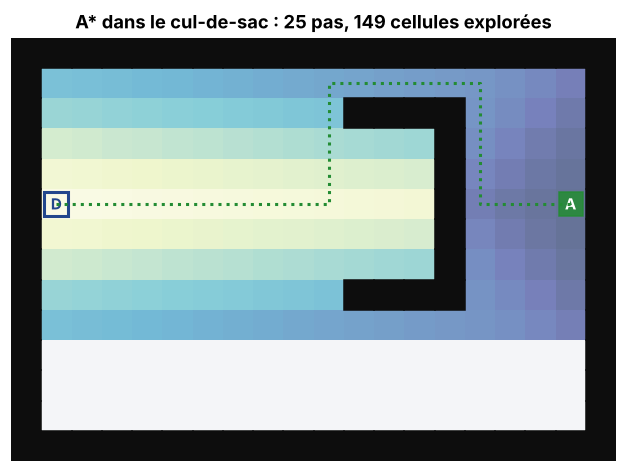

In [4]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def a_etoile(est_libre, depart, arrivee, interdites=frozenset(), poids_h=1.0):
    """Plus court chemin sur la grille. Retourne (chemin ou None, cellules explorées dans l'ordre)."""
    depart, arrivee = tuple(depart), tuple(arrivee)
    file = [(poids_h * manhattan(depart, arrivee), 0, depart)]   # (f, g, cellule)
    parent, cout = {depart: None}, {depart: 0}
    explorees = []
    while file:
        _, g, courante = heapq.heappop(file)
        if g > cout[courante]:
            continue                                  # entrée périmée de la file
        explorees.append(courante)
        if courante == arrivee:
            chemin = []
            while courante is not None:
                chemin.append(courante)
                courante = parent[courante]
            return chemin[::-1], explorees
        for a in DIRECTIONS:
            dx, dy = ACTIONS[a]
            voisine = (courante[0] + dx, courante[1] + dy)
            if not est_libre(voisine) or voisine in interdites:
                continue
            if g + 1 < cout.get(voisine, float("inf")):
                cout[voisine], parent[voisine] = g + 1, courante
                heapq.heappush(file, (g + 1 + poids_h * manhattan(voisine, arrivee), g + 1, voisine))
    return None, explorees


def action_vers(depuis, vers):
    delta = (vers[0] - depuis[0], vers[1] - depuis[1])
    return next(a for a in DIRECTIONS if ACTIONS[a] == delta)


def tracer_exploration(monde, chemin, explorees, ax, titre):
    ordre = np.full((monde.hauteur, monde.largeur), np.nan)
    for rang, (x, y) in enumerate(explorees):
        ordre[y, x] = rang
    dessiner_monde(monde, ax, plan=chemin, titre=titre)
    ax.imshow(np.ma.masked_invalid(ordre), extent=(0, monde.largeur, monde.hauteur, 0), cmap="YlGnBu", alpha=0.6, zorder=1)


monde = creer_scenario("piege")
chemin, explorees = a_etoile(monde.est_libre_statique, monde.depart, monde.objectif)
fig, ax = plt.subplots(figsize=(8, 5))
tracer_exploration(monde, chemin, explorees, ax, f"A* dans le cul-de-sac : {len(chemin) - 1} pas, {len(explorees)} cellules explorées")

Les cellules colorées sont celles qu'A* a examinées (du clair au foncé dans l'ordre d'exploration), le pointillé vert est le plan. A* contourne le U que l'agent réactif ne pouvait pas éviter.

### Exercice 1 : le rôle de l'heuristique

Le paramètre `poids_h` multiplie l'heuristique. Avec 0, A* devient l'algorithme de Dijkstra (aucune estimation). Avec une valeur supérieure à 1, l'heuristique surestime : la recherche fonce vers l'objectif, sans garantie d'optimalité. Comparez, pour `poids_h` valant 0, 1, 2 et 5, le nombre de cellules explorées, la longueur du chemin et le temps de calcul sur le scénario `entrepot`.

In [5]:
# À COMPLÉTER : une seule valeur pour l'instant.
monde = creer_scenario("entrepot", chariots=False)
for poids in [1.0]:
    chemin, explorees = a_etoile(monde.est_libre_statique, monde.depart, monde.objectif, poids_h=poids)
    print(f"poids_h={poids} : {len(chemin) - 1} pas, {len(explorees)} cellules explorées")

poids_h=1.0 : 26 pas, 100 cellules explorées


,poids_h,pas,cellules explorées,temps (ms)
0,0.0,26,160,0.520
1,1.0,26,100,0.325
2,2.0,26,51,0.082
3,5.0,30,40,0.068


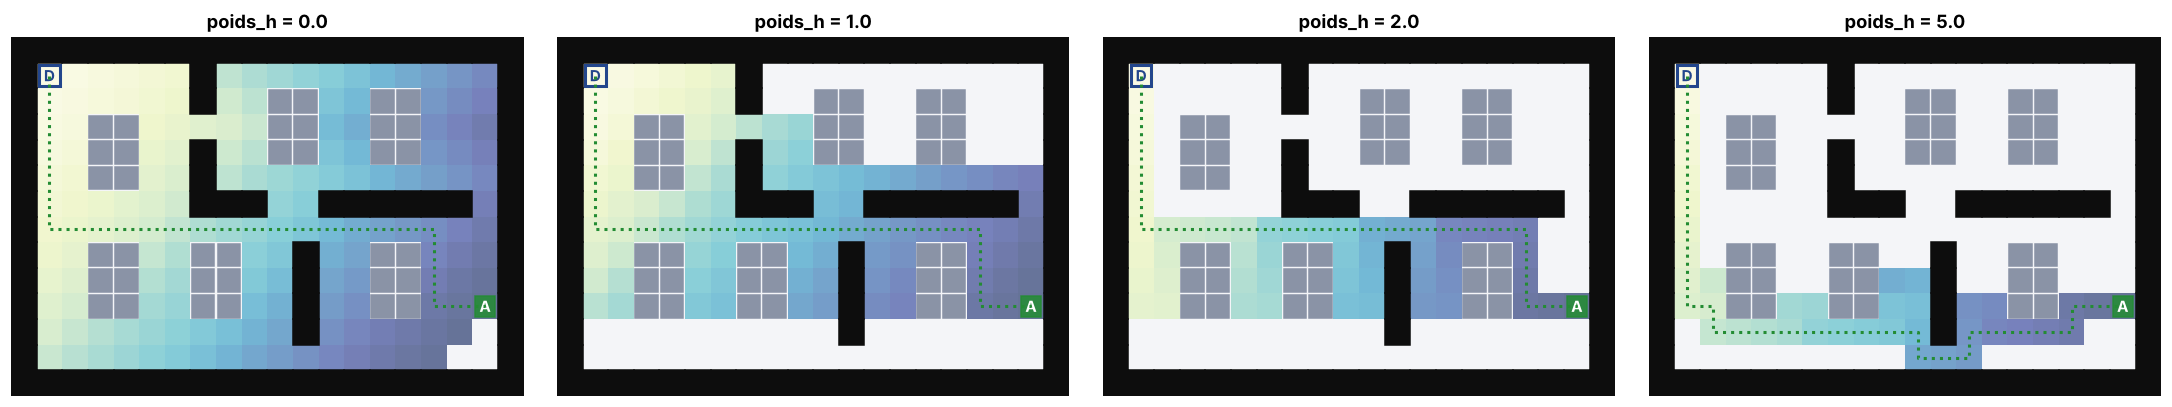

In [6]:
# Solution possible.
lignes = []
fig, axes = plt.subplots(1, 4, figsize=(20, 3.6))
for ax, poids in zip(axes, [0.0, 1.0, 2.0, 5.0]):
    debut = time.perf_counter()
    for _ in range(20):
        chemin, explorees = a_etoile(monde.est_libre_statique, monde.depart, monde.objectif, poids_h=poids)
    duree = (time.perf_counter() - debut) / 20 * 1000
    lignes.append({"poids_h": poids, "pas": len(chemin) - 1, "cellules explorées": len(explorees), "temps (ms)": round(duree, 3)})
    tracer_exploration(monde, chemin, explorees, ax, f"poids_h = {poids}")
plt.tight_layout()
pd.DataFrame(lignes)

Une heuristique plus forte réduit l'exploration, donc le temps de décision, mais peut allonger le chemin. Ce réglage entre qualité du plan et temps de calcul est un choix de conception courant en robotique embarquée.

### Le contrôleur délibératif

Il planifie une fois, puis déroule son plan en boucle ouverte : il suppose que chaque action réussit et ne consulte plus ses capteurs.

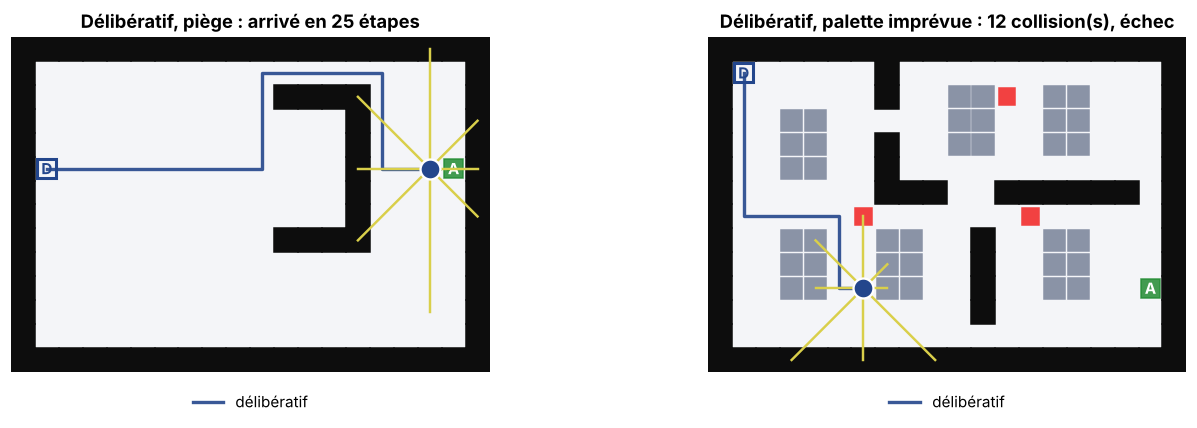

In [7]:
class Deliberatif:
    nom = "délibératif"

    def reinitialiser(self, monde):
        self.plan, explorees = a_etoile(monde.est_libre_statique, monde.depart, monde.objectif)
        self.explorees = len(explorees)
        self.indice = 0

    def decider(self, observation):
        if not self.plan or self.indice >= len(self.plan) - 1:
            return "ATTENDRE", {"couche": "deliberative", "raison": "plan terminé ou inexistant", "plan": []}
        action = action_vers(self.plan[self.indice], self.plan[self.indice + 1])
        reste = self.plan[self.indice:]
        self.indice += 1
        return action, {"couche": "deliberative", "raison": f"étape {self.indice} du plan initial", "plan": reste}


PALETTE_IMPREVUE = [Evenement(6, (6, 7))]     # une palette posée à l'étape 6 sur la route planifiée

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
t1 = simuler(creer_scenario("piege"), Deliberatif(), max_etapes=120)
dessiner_trace(t1, ax=axes[0], titre=f"Délibératif, piège : arrivé en {t1.bilan['etapes']} étapes")
t2 = simuler(creer_scenario("entrepot", evenements=PALETTE_IMPREVUE), Deliberatif(), max_etapes=120)
dessiner_trace(t2, ax=axes[1], titre=f"Délibératif, palette imprévue : {t2.bilan['collisions']} collision(s), {'arrivé' if t2.bilan['succes'] else 'échec'}")
plt.tight_layout()

**Lecture.** Le plan règle le cul-de-sac. En revanche, dès que le monde s'écarte du modèle (une palette absente de la carte), l'agent percute l'obstacle, puis continue de dérouler un plan qui ne correspond plus à sa position réelle.

## 4. Contrôleur hybride

Deux couches : la couche délibérative fournit le plan, la couche réactive vérifie le lidar avant chaque mouvement et garde le dernier mot. Si la cellule visée est occupée, l'agent attend une étape, mémorise l'obstacle pendant quelques étapes et replanifie depuis sa position observée.

Décisions de la couche réactive :
  t= 10 en [5, 7] : obstacle imprévu en E : arrêt, replanification


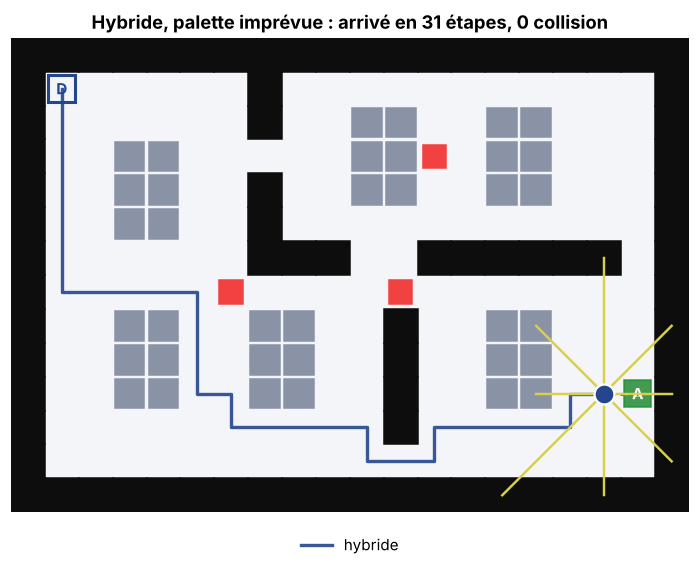

In [8]:
class Hybride:
    nom = "hybride"

    def __init__(self, memoire_obstacle=6):
        self.memoire_obstacle = memoire_obstacle

    def reinitialiser(self, monde):
        self.monde = monde
        self.plan = None
        self.bloquees = {}            # cellule : étape jusqu'à laquelle on la considère occupée
        self.replanifications = 0

    def decider(self, observation):
        t, position = observation["etape"], tuple(observation["position"])
        self.bloquees = {c: fin for c, fin in self.bloquees.items() if fin > t}
        # Couche délibérative : (re)planifier si nécessaire.
        if self.plan is None or position not in self.plan:
            self.plan, _ = a_etoile(self.monde.est_libre_statique, position, self.monde.objectif, interdites=set(self.bloquees))
            self.replanifications += 1
            if self.plan is None:
                return "ATTENDRE", {"couche": "reactive", "raison": "aucun passage pour l'instant", "plan": []}
        i = self.plan.index(position)
        if i >= len(self.plan) - 1:
            return "ATTENDRE", {"couche": "deliberative", "raison": "objectif atteint", "plan": []}
        action = action_vers(position, self.plan[i + 1])
        # Couche réactive : le lidar a le dernier mot.
        if observation["lidar"][action] <= 1:
            self.bloquees[self.plan[i + 1]] = t + self.memoire_obstacle
            self.plan = None
            return "ATTENDRE", {"couche": "reactive", "raison": f"obstacle imprévu en {action} : arrêt, replanification", "plan": []}
        return action, {"couche": "deliberative", "raison": f"suivi du plan : {action}", "plan": self.plan[i:]}


t3 = simuler(creer_scenario("entrepot", evenements=[Evenement(6, (6, 7))]), Hybride(), max_etapes=120)
dessiner_trace(t3, titre=f"Hybride, palette imprévue : arrivé en {t3.bilan['etapes']} étapes, {t3.bilan['collisions']} collision")
print("Décisions de la couche réactive :")
for e in t3.vers_dict()["etapes"]:
    if e["decision"]["couche"] == "reactive":
        print(f"  t={e['t']:3d} en {e['etat']['robot']} : {e['decision']['raison']}")

## 5. Comparaison sur les mêmes scénarios

Les trois contrôleurs, trois scénarios identiques, quatre mesures : réussite, nombre d'étapes, collisions, temps de décision.

In [9]:
SCENARIOS = {
    "ouvert": lambda: creer_scenario("ouvert"),
    "piège": lambda: creer_scenario("piege"),
    "entrepôt + palette": lambda: creer_scenario("entrepot", evenements=[Evenement(6, (6, 7))]),
}
CONTROLEURS = {"réactif": Reactif, "délibératif": Deliberatif, "hybride": Hybride}


def comparer(scenarios, controleurs, max_etapes=120):
    traces, lignes = {}, []
    for nom_s, fabrique in scenarios.items():
        for nom_c, classe in controleurs.items():
            trace = simuler(fabrique(), classe(), max_etapes=max_etapes, module=3)
            traces[(nom_s, nom_c)] = trace
            b = trace.bilan
            lignes.append({"scénario": nom_s, "contrôleur": nom_c, "succès": b["succes"], "étapes": b["etapes"],
                           "collisions": b["collisions"], "décision moy. (ms)": round(b["temps_decision_moyen_ms"], 4),
                           "décision max (ms)": round(b["temps_decision_max_ms"], 3)})
    return traces, pd.DataFrame(lignes)


traces, bilan = comparer(SCENARIOS, CONTROLEURS)
bilan

,scénario,contrôleur,succès,étapes,collisions,décision moy. (ms),décision max (ms)
0,ouvert,réactif,True,26,0,0.0012,0.006
1,ouvert,délibératif,True,26,0,0.0015,0.006
2,ouvert,hybride,True,26,0,0.0176,0.407
3,piège,réactif,False,120,0,0.0011,0.004
4,piège,délibératif,True,25,0,0.0013,0.004
5,piège,hybride,True,25,0,0.0115,0.241
6,entrepôt + palette,réactif,False,120,0,0.0013,0.006
7,entrepôt + palette,délibératif,False,120,12,0.0005,0.004
8,entrepôt + palette,hybride,True,31,0,0.0101,0.171


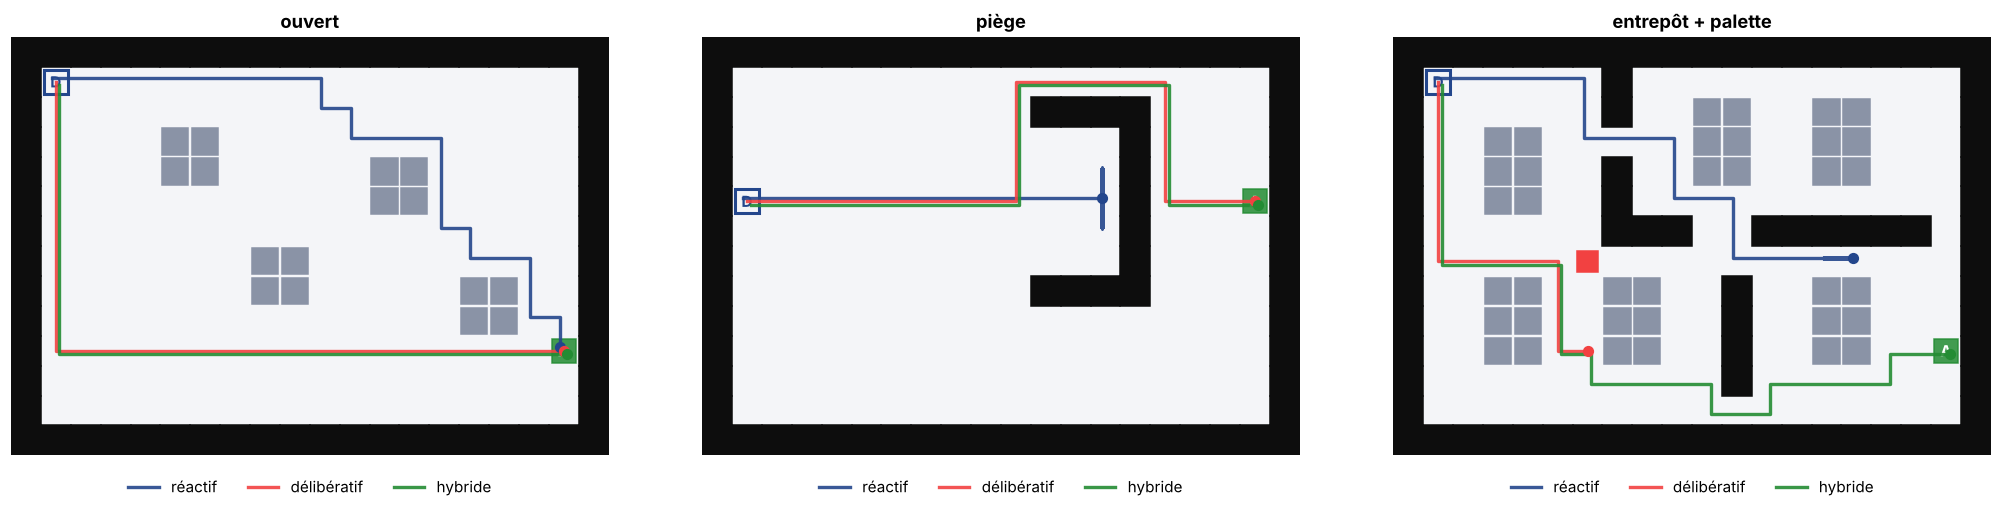

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.4))
for ax, nom_s in zip(axes, SCENARIOS):
    monde_final = traces[(nom_s, "hybride")].vers_dict()
    dessiner_monde(monde_final["monde"], ax, titre=nom_s,
                   trajectoires={c: traces[(nom_s, c)].trajectoire() for c in CONTROLEURS},
                   obstacles=monde_final["bilan"]["palettes_finales"])
plt.tight_layout()

**Lecture du temps de décision.** Le réactif décide en temps constant. Le délibératif paie tout au départ (dans `reinitialiser`, hors mesure ici) puis ne calcule plus rien. L'hybride a un temps moyen faible mais un maximum plus élevé : les pics correspondent aux replanifications. En embarqué, c'est le temps maximal qui compte pour garantir une réaction dans les délais.

### Vérification avec les contrôleurs du paquet

Le paquet `ascent_agents` contient des versions des mêmes architectures, utilisées par la scène 3D du site. Elles doivent donner les mêmes verdicts que les nôtres.

In [11]:
_, bilan_paquet = comparer(SCENARIOS, {"réactif": AgentReactif, "délibératif": AgentDeliberatif, "hybride": AgentHybride})
fusion = bilan[["scénario", "contrôleur", "succès", "étapes", "collisions"]].merge(
    bilan_paquet[["scénario", "contrôleur", "succès", "étapes", "collisions"]], on=["scénario", "contrôleur"], suffixes=(" notebook", " paquet"))
fusion

,scénario,contrôleur,succès notebook,étapes notebook,collisions notebook,succès paquet,étapes paquet,collisions paquet
0,ouvert,réactif,True,26,0,True,26,0
1,ouvert,délibératif,True,26,0,True,26,0
2,ouvert,hybride,True,26,0,True,26,0
3,piège,réactif,False,120,0,False,120,0
4,piège,délibératif,True,25,0,True,25,0
5,piège,hybride,True,25,0,True,25,0
6,entrepôt + palette,réactif,False,120,0,False,120,0
7,entrepôt + palette,délibératif,False,120,12,False,120,12
8,entrepôt + palette,hybride,True,31,0,True,30,0


Les verdicts concordent. Un écart d'une étape est possible pour l'hybride : notre version s'arrête une étape avant de replanifier, celle du paquet replanifie dans la même étape.

### Deux scénarios à porte unique

Pour étudier le comportement face aux obstacles, construisons un entrepôt sur mesure : deux halls séparés par une cloison, une porte au milieu et un passage éloigné en bas. Un obstacle dans la porte impose soit d'attendre, soit de faire un long détour.

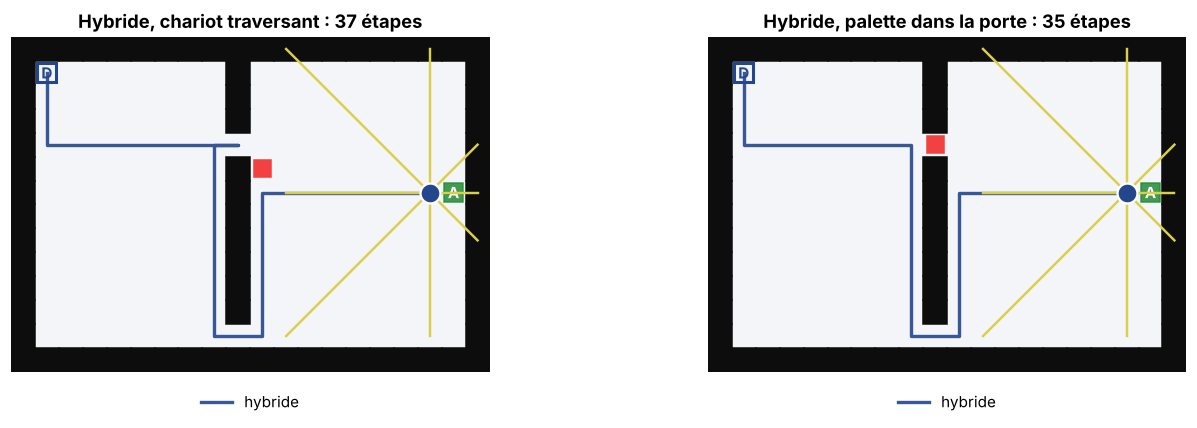

In [12]:
PLAN_PORTE = [
    "####################",
    "#D.......#.........#",
    "#........#.........#",
    "#........#.........#",
    "#..................#",
    "#........#.........#",
    "#........#........A#",
    "#........#.........#",
    "#........#.........#",
    "#........#.........#",
    "#........#.........#",
    "#........#.........#",
    "#..................#",
    "####################",
]
SCENARIOS_PORTE = {
    # Un chariot coupe la sortie de la porte, puis s'éloigne : obstacle mobile.
    "chariot traversant": lambda: Entrepot(plan=PLAN_PORTE, nom="porte", chariots=[Chariot(de=(10, 3), a=(10, 5), periode=2)]),
    # Une palette est déposée dans la porte à l'étape 3 : obstacle fixe.
    "palette dans la porte": lambda: Entrepot(plan=PLAN_PORTE, nom="porte", evenements=[Evenement(3, (9, 4))]),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nom_s, fabrique) in zip(axes, SCENARIOS_PORTE.items()):
    trace = simuler(fabrique(), Hybride(), max_etapes=150)
    dessiner_trace(trace, ax=ax, titre=f"Hybride, {nom_s} : {trace.bilan['etapes']} étapes")
plt.tight_layout()

### Exercice 2 : la mémoire des obstacles

Le contrôleur hybride oublie un obstacle après `memoire_obstacle` étapes. Testez les valeurs 1, 3, 6 et 30 sur les deux scénarios à porte. Que se passe-t-il avec la valeur 1, et pourquoi les valeurs suivantes donnent-elles le même résultat ?

In [13]:
# À COMPLÉTER.
for memoire in [6]:
    b = simuler(SCENARIOS_PORTE["palette dans la porte"](), Hybride(memoire_obstacle=memoire), max_etapes=150).bilan
    print(f"mémoire {memoire} : succès {b['succes']}, {b['etapes']} étapes, {b['collisions']} collision(s)")

mémoire 6 : succès True, 35 étapes, 0 collision(s)


In [14]:
# Solution possible.
lignes = []
for memoire in [1, 3, 6, 30]:
    for nom_s, fabrique in SCENARIOS_PORTE.items():
        agent = Hybride(memoire_obstacle=memoire)
        b = simuler(fabrique(), agent, max_etapes=150).bilan
        lignes.append({"mémoire": memoire, "scénario": nom_s, "succès": b["succes"], "étapes": b["etapes"], "replanifications": agent.replanifications})
pd.DataFrame(lignes).pivot(index="mémoire", columns="scénario", values=["succès", "étapes", "replanifications"])

succès                                   étapes  \
scénario chariot traversant palette dans la porte chariot traversant   
mémoire                                                                
1                     False                 False                150   
3                      True                  True                 37   
6                      True                  True                 37   
30                     True                  True                 37   

                                 replanifications                        
scénario palette dans la porte chariot traversant palette dans la porte  
mémoire                                                                  
1                          150                138                   140  
3                           35                  2                     2  
6                           35                  2                     2  
30                          35                  2                     2

Avec une mémoire de 1, l'obstacle est oublié avant la replanification : A* redonne le même chemin et le robot bute indéfiniment sur la porte. Dès que la mémoire couvre la replanification, le détour est trouvé. Les valeurs plus longues ne changent rien ici, car ce contrôleur ne replanifie que lorsque son plan devient inapplicable. Avec un agent qui replanifie périodiquement pour chercher un raccourci, une mémoire trop longue lui ferait éviter durablement un passage libéré depuis longtemps. Distinguer les obstacles fixes des obstacles mobiles (par exemple en observant s'ils bougent) lève ce compromis : c'est une tâche de perception, pas de décision.

## 6. Complexité croissante et limites

Faisons varier la densité de rayonnages d'entrepôts aléatoires, avec un léger glissement des roues (5 % des déplacements ne s'exécutent pas). Le glissement est un écart entre le modèle et le monde réel : il n'apparaît dans aucune carte.

succès                  collisions                
contrôleur délibératif hybride réactif délibératif hybride réactif
densité                                                           
0.05               0.2     1.0     0.9         1.6     0.0     0.0
0.12               0.2     1.0     0.8         4.1     0.0     0.0
0.20               0.2     1.0     0.7         4.3     0.0     0.0
0.28               0.2     1.0     0.5         5.6     0.0     0.0

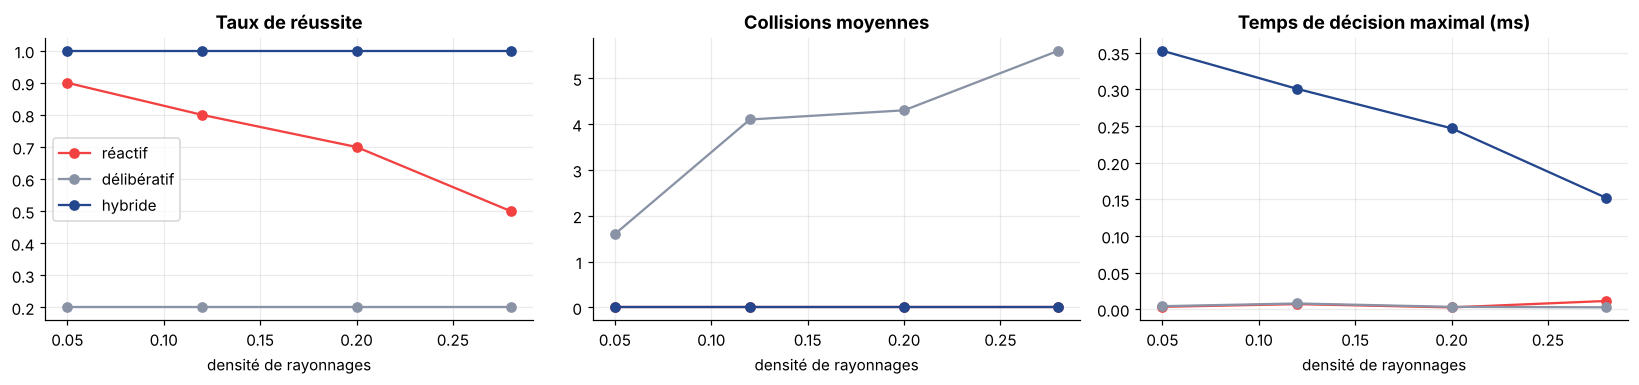

In [15]:
PARAMETRES_COMPLEXITE = {
    "densites": [0.05, 0.12, 0.20, 0.28],
    "graines": range(10),
    "glissement": 0.05,
    "max_etapes": 150,
}

lignes = []
for densite in PARAMETRES_COMPLEXITE["densites"]:
    for g in PARAMETRES_COMPLEXITE["graines"]:
        for nom_c, classe in CONTROLEURS.items():
            monde = entrepot_aleatoire(g, densite=densite, glissement=PARAMETRES_COMPLEXITE["glissement"])
            b = simuler(monde, classe(), max_etapes=PARAMETRES_COMPLEXITE["max_etapes"]).bilan
            lignes.append({"densité": densite, "graine": g, "contrôleur": nom_c, "succès": b["succes"], "collisions": b["collisions"],
                           "étapes": b["etapes"], "décision max (ms)": b["temps_decision_max_ms"]})
complexite = pd.DataFrame(lignes)
resume = complexite.groupby(["densité", "contrôleur"])[["succès", "collisions", "décision max (ms)"]].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, colonne, titre in zip(axes, ["succès", "collisions", "décision max (ms)"], ["Taux de réussite", "Collisions moyennes", "Temps de décision maximal (ms)"]):
    for (nom_c, couleur) in zip(CONTROLEURS, [ROUGE, GRIS, BLEU]):
        ax.plot(PARAMETRES_COMPLEXITE["densites"], resume.xs(nom_c, level="contrôleur")[colonne], "o-", color=couleur, label=nom_c)
    ax.set(xlabel="densité de rayonnages", title=titre)
axes[0].legend()
plt.tight_layout()
resume[["succès", "collisions"]].unstack().round(2)

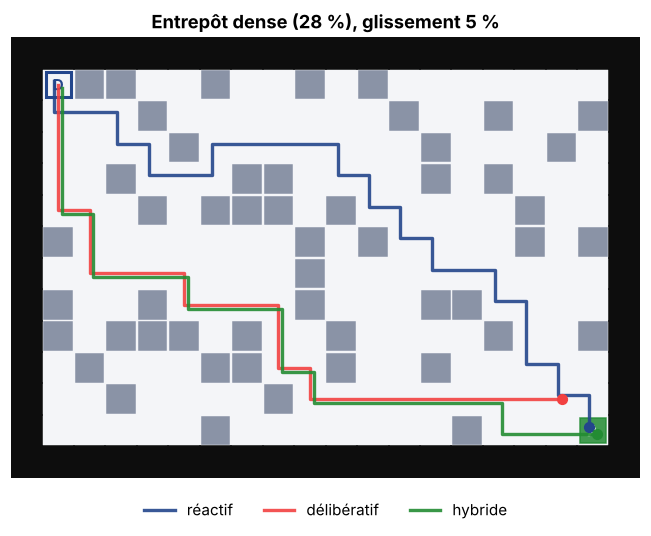

In [16]:
# Un exemple à forte densité, pour voir les trois comportements.
monde_dense = lambda: entrepot_aleatoire(3, densite=0.28, glissement=0.05)
fig, ax = plt.subplots(figsize=(8, 5.2))
traj = {nom: simuler(monde_dense(), classe(), max_etapes=150).trajectoire() for nom, classe in CONTROLEURS.items()}
dessiner_monde(monde_dense(), ax, trajectoires=traj, titre="Entrepôt dense (28 %), glissement 5 %");

**Limites identifiées**

- **Réactif** : sa réussite chute quand la densité augmente, car les minimums locaux se multiplient. Son temps de décision reste constant et minimal.
- **Délibératif** : la complexité de la carte ne le gêne pas, mais le moindre glissement décale son exécution par rapport au plan. Il accumule alors les collisions sans s'en apercevoir.
- **Hybride** : il conserve un taux de réussite élevé, au prix de replanifications dont le coût croît avec la taille de la carte.

### Défis d'implémentation en environnement réel

| Défi | Manifestation | Réponse d'architecture |
|---|---|---|
| Modèle inexact | Carte périmée, palette oubliée, sol glissant | Boucle fermée : comparer en permanence le plan à l'observation |
| Temps de calcul borné | La replanification dépasse la période de commande | Couche réactive à temps constant, planification en tâche de fond |
| Perception incertaine | Lidar bruité, localisation approximative | Filtrage et croyance probabiliste (module 5) |
| Sûreté | Présence humaine | Arrêt d'urgence indépendant du logiciel de décision |
| Arbitrage des couches | Le plan dit d'avancer, le réflexe dit d'arrêter | Priorité explicite, la sécurité l'emporte |
| Validation | Comportement différent selon les aléas | Campagnes de tests statistiques (module 6) |

## 7. TP de conception (syllabus) : l'architecture d'un agent pour un cas pratique

**Cas pratique.** Un robot de réapprovisionnement travaille de jour dans l'entrepôt de référence. Des chariots conduits par des opérateurs circulent dans les allées, et s'écartent en général au bout de quelques secondes. Le robot doit livrer vite, sans collision, et son calculateur embarqué est modeste.

### Étape 1 : fiche de conception

Complétez la fiche. Chaque ligne correspond à une décision d'architecture à justifier.

In [17]:
# À COMPLÉTER.
fiche = {
    "Perception : capteurs et traitement": "...",
    "Modèle du monde : que contient-il ?": "...",
    "Couche délibérative : quand planifie-t-elle ?": "...",
    "Couche réactive : quelles règles de sécurité ?": "...",
    "Arbitrage : qui a le dernier mot ?": "...",
    "Face à un chariot : attendre ou contourner ?": "...",
    "Mesures de validation": "...",
}
pd.set_option("display.max_colwidth", 140)
pd.DataFrame.from_dict(fiche, orient="index", columns=["choix et justification"])

,choix et justification
Perception : capteurs et traitement,...
Modèle du monde : que contient-il ?,...
Couche délibérative : quand planifie-t-elle ?,...
Couche réactive : quelles règles de sécurité ?,...
Arbitrage : qui a le dernier mot ?,...
Face à un chariot : attendre ou contourner ?,...
Mesures de validation,...


In [18]:
# Proposition de fiche (d'autres choix argumentés sont recevables).
fiche_proposee = {
    "Perception : capteurs et traitement": "Lidar 8 rayons et localisation. Distinguer obstacle fixe et obstacle mobile en comparant deux lectures.",
    "Modèle du monde : que contient-il ?": "Carte statique (murs, rayonnages) et obstacles temporaires avec durée de validité.",
    "Couche délibérative : quand planifie-t-elle ?": "Au départ, puis seulement quand le plan devient inapplicable, pour ménager le calculateur.",
    "Couche réactive : quelles règles de sécurité ?": "Ne jamais avancer vers une cellule que le lidar voit occupée.",
    "Arbitrage : qui a le dernier mot ?": "La couche réactive, toujours.",
    "Face à un chariot : attendre ou contourner ?": "Attendre quelques étapes (le chariot s'écarte souvent), puis contourner si le passage reste bloqué.",
    "Mesures de validation": "Taux de réussite, collisions (objectif zéro), étapes, temps de décision maximal, nombre de replanifications.",
}
pd.DataFrame.from_dict(fiche_proposee, orient="index", columns=["choix et justification"])

,choix et justification
Perception : capteurs et traitement,Lidar 8 rayons et localisation. Distinguer obstacle fixe et obstacle mobile en comparant deux lectures.
Modèle du monde : que contient-il ?,"Carte statique (murs, rayonnages) et obstacles temporaires avec durée de validité."
Couche délibérative : quand planifie-t-elle ?,"Au départ, puis seulement quand le plan devient inapplicable, pour ménager le calculateur."
Couche réactive : quelles règles de sécurité ?,Ne jamais avancer vers une cellule que le lidar voit occupée.
Arbitrage : qui a le dernier mot ?,"La couche réactive, toujours."
Face à un chariot : attendre ou contourner ?,"Attendre quelques étapes (le chariot s'écarte souvent), puis contourner si le passage reste bloqué."
Mesures de validation,"Taux de réussite, collisions (objectif zéro), étapes, temps de décision maximal, nombre de replanifications."


### Étape 2 : implémenter une variante

Implémentez la stratégie « attendre puis contourner » : quand la couche réactive détecte un obstacle, l'agent patiente jusqu'à `patience` étapes avant de mémoriser l'obstacle et de replanifier. Si le passage se libère entre temps, il reprend son plan sans détour. Comparez les valeurs de `patience` 0, 1, 2 et 4 sur les deux scénarios à porte et sur l'entrepôt avec palette imprévue.

La classe ci-dessous hérite de notre `Hybride`. Pour l'instant, elle se comporte exactement comme lui.

In [19]:
# À COMPLÉTER : utilisez self.patience et un compteur d'attente.
class HybridePatient(Hybride):
    nom = "hybride patient"

    def __init__(self, patience=2, **kw):
        super().__init__(**kw)
        self.patience = patience

    def decider(self, observation):
        return super().decider(observation)


for nom_s, fabrique in SCENARIOS_PORTE.items():
    b = simuler(fabrique(), HybridePatient(patience=2), max_etapes=150).bilan
    print(nom_s, {k: b[k] for k in ("succes", "etapes", "collisions")})

chariot traversant {'succes': True, 'etapes': 37, 'collisions': 0}
palette dans la porte {'succes': True, 'etapes': 35, 'collisions': 0}


scénario,chariot traversant,entrepôt + palette,palette dans la porte
patience,,,
0,37,31,35
1,25,32,36
2,26,33,37
4,28,35,39


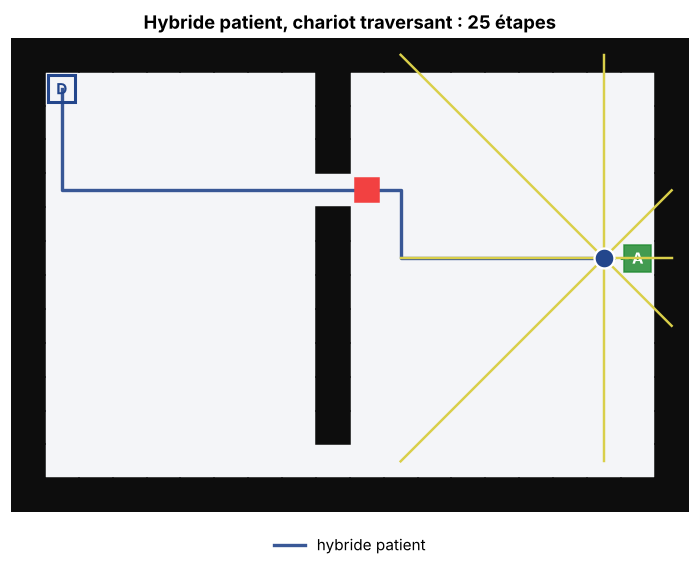

In [20]:
# Solution possible.
class HybridePatientSolution(Hybride):
    nom = "hybride patient"

    def __init__(self, patience=2, **kw):
        super().__init__(**kw)
        self.patience = patience

    def reinitialiser(self, monde):
        super().reinitialiser(monde)
        self.attente = 0

    def decider(self, observation):
        position = tuple(observation["position"])
        if self.plan and position in self.plan:
            i = self.plan.index(position)
            if i < len(self.plan) - 1:
                action = action_vers(position, self.plan[i + 1])
                if observation["lidar"][action] <= 1 and self.attente < self.patience:
                    self.attente += 1
                    return "ATTENDRE", {"couche": "reactive", "raison": f"obstacle en {action} : patience {self.attente} sur {self.patience}", "plan": self.plan[i:]}
        self.attente = 0
        return super().decider(observation)


SCENARIOS_TP = {**SCENARIOS_PORTE, "entrepôt + palette": SCENARIOS["entrepôt + palette"]}
lignes, meilleure = [], None
for patience in [0, 1, 2, 4]:
    for nom_s, fabrique in SCENARIOS_TP.items():
        agent = HybridePatientSolution(patience=patience)
        trace = simuler(fabrique(), agent, max_etapes=150, module=3, identifiant=f"m3-tp-patient-{patience}")
        b = trace.bilan
        lignes.append({"patience": patience, "scénario": nom_s, "étapes": b["etapes"], "collisions": b["collisions"], "replanifications": agent.replanifications})
        if nom_s == "chariot traversant" and b["succes"] and (meilleure is None or b["etapes"] < meilleure.bilan["etapes"]):
            meilleure = trace
resultats_tp = pd.DataFrame(lignes)
if meilleure is not None:
    meilleure.enregistrer(RESULTATS / "m3_tp_hybride_patient.json")     # rejouable dans la scène 3D du site
if meilleure is not None:
    dessiner_trace(meilleure, titre=f"Hybride patient, chariot traversant : {meilleure.bilan['etapes']} étapes")
resultats_tp.pivot(index="patience", columns="scénario", values="étapes")

Face au chariot qui traverse, une étape de patience évite un long détour. Face à un obstacle fixe, chaque étape de patience est perdue. La bonne valeur dépend de la proportion d'obstacles mobiles dans l'environnement visé : elle se choisit par la mesure, sur des scénarios représentatifs, et non par intuition.

## Synthèse du module

- L'architecture réactive décide en temps constant à partir de la seule mesure courante et échoue dans les minimums locaux.
- L'architecture délibérative calcule un plan optimal sur son modèle et devient fragile dès que le monde s'en écarte (obstacle imprévu, glissement).
- L'architecture hybride confie la vision d'ensemble à un planificateur et la sécurité à une couche réactive prioritaire, ce qui impose de concevoir explicitement l'arbitrage.
- Le temps de décision maximal, et non le temps moyen, dimensionne un système embarqué.
- Chaque paramètre d'architecture (heuristique, mémoire des obstacles, patience) est un compromis qui se règle par la mesure sur des scénarios représentatifs.

## Auto-évaluation

Sans relire le notebook, cochez ce que vous sauriez refaire seul sur un nouveau problème :

- [ ] Je sais programmer un contrôleur réactif, un contrôleur délibératif et un contrôleur hybride.
- [ ] Je sais prévoir lequel échoue dans un scénario donné et expliquer pourquoi.
- [ ] Je sais comparer des architectures sur des mesures (réussite, collisions, temps de décision).
- [ ] Je sais proposer une architecture pour un cas pratique et défendre ce choix.

Pour chaque case que vous hésitez à cocher, reprenez la partie correspondante et refaites son exercice sans regarder la solution. Les trois questions de la section « Vérifiez vos acquis » du module, sur le site, complètent ce bilan.